# Reproduction: *Brain tumor classification using MRI images and deep learning techniques*
Wong, Su, Yeong, Holderbaum & Yang (2025), **PLoS ONE 20(5): e0322624**

**Target results (test set, 655 images):** overall accuracy **99.24 %** (650/655), macro sensitivity 99.18 %, macro specificity 99.75 %,
confusion matrix in Fig 4, per-class precision/recall/F1 in Table 3.

**Pipeline as described in the paper**
1. Data: Figshare + SARTAJ + Br35H, 4 classes (7,023 images). This combination is exactly the Kaggle
   *Brain Tumor MRI Dataset* by Masoud Nickparvar: its `Training/` folder has 5,712 images, and ×3 gives 17,136. Its `Testing/` folder has 1,311 images, which split 50/50 into the paper's 656 validation and 655 test images.
2. Grayscale conversion. Offline augmentation (shear, zoom, horizontal flip) creates **2 augmented copies per training image**, so the training set grows 3× to 17,136 images.
3. Rescale pixel values by 1/255.
4. Model: VGG16 (ImageNet, frozen, 224×224×3) → Flatten → Dense(256, ReLU) → Dense(4, softmax).
5. Stage 1: Adam with lr 1e-3, 50 epochs, batch 32, 179 steps per epoch, 21 validation steps.
6. Stage 2: freeze the first 10 VGG layers and unfreeze the rest. Adam with lr 1e-4, 50 more epochs.
7. Evaluation: classification report, confusion matrix, per-class sensitivity and specificity.
8. Dash web app.

**Assumptions** (the paper does not specify these; each one is a single setting in the config cell):
- shear range 0.2, zoom range 0.2, `fill_mode='nearest'`. Fig 2's smeared bottom edge is consistent with nearest-fill.
- Loss is categorical cross-entropy.
- No on-the-fly augmentation during training. The augmentation happens offline, before training.
- Early stopping is off. Fig 3 shows the full 50 + 50 epochs.
- "First ten layers" means `base_model.layers[:10]` in Keras VGG16 (input → block3_conv3). Blocks 4–5 are therefore trainable.
- Inputs are rescaled by 1/255, not VGG's `preprocess_input`, as the paper describes.

**Runtime:** use a GPU (Colab or Kaggle T4 or better). The paper trained on a CPU laptop, which would take days.

In [1]:
   import tensorflow as tf
   v = ".".join(tf.__version__.split(".")[:2])
   %pip install -q seaborn "tf_keras=={v}.*"

Note: you may need to restart the kernel to use updated packages.


In [2]:
# If needed:  pip install tf_keras kagglehub seaborn scikit-learn pillow dash
import os, random, math, shutil, hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf

# The paper used the Keras 2 API (ImageDataGenerator / flow_from_directory).
# Keras 3 (TF >= 2.16) removed ImageDataGenerator, so use the tf_keras package there.
try:
    import tf_keras as keras
except ImportError:
    from tensorflow import keras
_img = keras.preprocessing.image
ImageDataGenerator, load_img, img_to_array, array_to_img = (
    _img.ImageDataGenerator, _img.load_img, _img.img_to_array, _img.array_to_img)
VGG16 = keras.applications.VGG16
layers, models, optimizers, callbacks = keras.layers, keras.models, keras.optimizers, keras.callbacks
from sklearn.metrics import classification_report, confusion_matrix

print("TF", tf.__version__, "| Keras", keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TF 2.20.0 | Keras 2.20.1 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Configuration

In [3]:
SEED = 42

DATA_ROOT = "/kaggle/input"       # folder containing Training/ and Testing/ ; None -> download with kagglehub
WORK_DIR  = Path("work")         # processed data, models and figures are written here

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
N_AUG_PER_IMAGE = 2              # paper: 2 augmented copies per original -> 3x training set
SHEAR_RANGE = 0.2                # ASSUMPTION (value not given in paper)
ZOOM_RANGE = 0.2                 # ASSUMPTION (value not given in paper)
ONLINE_AUGMENTATION = False      # ASSUMPTION: paper augments offline only

WEIGHTS = "imagenet"
LR_STAGE1, LR_STAGE2 = 1e-3, 1e-4
EPOCHS_STAGE1, EPOCHS_STAGE2 = 50, 50
N_FROZEN_STAGE2 = 10             # "first ten layers nontrainable"
STEPS_PER_EPOCH = 179            # paper value (= ceil(5712/32)); use None for a full pass over all 17,136 images
VALIDATION_STEPS = 21            # paper value (= ceil(656/32))
USE_EARLY_STOPPING = False       # paper mentions it, but Fig 3 shows full 50+50 epochs
EARLY_STOP_PATIENCE = 10

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]   # alphabetical = flow_from_directory order
DISPLAY = {"glioma": "glioma tumor", "meningioma": "meningioma tumor",
           "notumor": "no tumor", "pituitary": "pituitary tumor"}

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
WORK_DIR.mkdir(parents=True, exist_ok=True)

## 2. Get the dataset
Kaggle: `masoudnickparvar/brain-tumor-mri-dataset`. Either set `DATA_ROOT` to an extracted copy, or let `kagglehub` download it.
On a Kaggle notebook you can also attach the dataset and set `DATA_ROOT="/kaggle/input/brain-tumor-mri-dataset"`.

In [4]:
if DATA_ROOT is None:
    import kagglehub
    DATA_ROOT = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

def find_dir(root, name):
    for dirpath, dirnames, _ in os.walk(root):
        if name in dirnames:
            return Path(dirpath) / name
    raise FileNotFoundError(f"{name}/ not found under {root}")

RAW_TRAIN = find_dir(DATA_ROOT, "Training")
RAW_TEST  = find_dir(DATA_ROOT, "Testing")
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def list_images(d):
    return sorted(p for p in Path(d).iterdir() if p.suffix.lower() in IMG_EXT)

counts = pd.DataFrame({
    "Training": {c: len(list_images(RAW_TRAIN / c)) for c in CLASSES},
    "Testing":  {c: len(list_images(RAW_TEST / c)) for c in CLASSES},
})
counts["Total"] = counts.sum(axis=1)
counts.loc["TOTAL"] = counts.sum()
# Paper totals: pituitary 1757, glioma 1621, meningioma 1645, no tumor 2000 (7023); train 5712 -> x3 = 17136
counts

,Training,Testing,Total
glioma,1400,400,1800
meningioma,1400,400,1800
notumor,1400,400,1800
pituitary,1400,400,1800
TOTAL,5600,1600,7200


## 3. Split, convert to grayscale, augment offline (the paper's `concatenate_images`)
- Validation and test sets: `Testing/` is split 50/50 per class, with validation taking the extra image. This gives 150/153/203/150 for validation and 150/153/202/150 for test, matching the paper.
- Training set: each image is saved as a grayscale PNG together with 2 augmented copies, giving 17,136 images.

In [5]:
PROC = WORK_DIR / "data"
TRAIN_DIR, VAL_DIR, TEST_DIR = PROC / "train", PROC / "val", PROC / "test"

offline_aug = ImageDataGenerator(shear_range=SHEAR_RANGE, zoom_range=ZOOM_RANGE,
                                 horizontal_flip=True, fill_mode="nearest")

def to_gray_array(path):
    return img_to_array(load_img(path, color_mode="grayscale", target_size=IMG_SIZE))  # (224,224,1)

def save_png(arr, path):
    array_to_img(arr, scale=False).save(path)

def concatenate_images(src_class_dir, dst_class_dir, n_aug=N_AUG_PER_IMAGE):
    dst_class_dir.mkdir(parents=True, exist_ok=True)
    for p in list_images(src_class_dir):
        x = to_gray_array(p)
        save_png(x, dst_class_dir / f"{p.stem}.png")
        for k in range(n_aug):
            save_png(offline_aug.random_transform(x, seed=None), dst_class_dir / f"{p.stem}_aug{k}.png")

if PROC.exists():
    shutil.rmtree(PROC)
rng = random.Random(SEED)
for c in CLASSES:
    concatenate_images(RAW_TRAIN / c, TRAIN_DIR / c)
    files = list_images(RAW_TEST / c)
    rng.shuffle(files)
    n_val = math.ceil(len(files) / 2)
    for split_dir, subset in [(VAL_DIR, files[:n_val]), (TEST_DIR, files[n_val:])]:
        (split_dir / c).mkdir(parents=True, exist_ok=True)
        for p in subset:
            save_png(to_gray_array(p), split_dir / c / f"{p.stem}.png")

split_counts = pd.DataFrame({s: {c: len(list((d / c).glob("*.png"))) for c in CLASSES}
                             for s, d in [("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR)]})
split_counts.loc["TOTAL"] = split_counts.sum()
# Paper: train 3963/4017/4785/4371 = 17136 ; val 150/153/203/150 = 656 ; test 150/153/202/150 = 655
split_counts

,train,val,test
glioma,4200,200,200
meningioma,4200,200,200
notumor,4200,200,200
pituitary,4200,200,200
TOTAL,16800,800,800


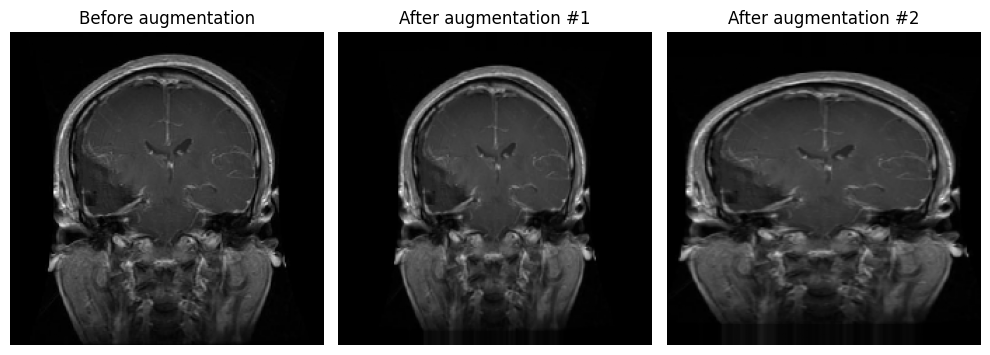

In [6]:
# Fig 2: before vs after augmentation
c = "glioma"
stem = list_images(RAW_TRAIN / c)[0].stem
fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
for a, (title, f) in zip(ax, [("Before augmentation", f"{stem}.png"),
                              ("After augmentation #1", f"{stem}_aug0.png"),
                              ("After augmentation #2", f"{stem}_aug1.png")]):
    a.imshow(Image.open(TRAIN_DIR / c / f), cmap="gray"); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.savefig(WORK_DIR / "fig2_augmentation.png", dpi=150); plt.show()

## 4. Data generators (rescale 1/255; grayscale → 3 channels for VGG16)

In [7]:
if ONLINE_AUGMENTATION:
    train_datagen = ImageDataGenerator(rescale=1/255, shear_range=SHEAR_RANGE,
                                       zoom_range=ZOOM_RANGE, horizontal_flip=True)
else:
    train_datagen = ImageDataGenerator(rescale=1/255)
eval_datagen = ImageDataGenerator(rescale=1/255)

common = dict(target_size=IMG_SIZE, color_mode="rgb", batch_size=BATCH_SIZE,
              class_mode="categorical", classes=CLASSES)
train_gen = train_datagen.flow_from_directory(TRAIN_DIR, shuffle=True, seed=SEED, **common)
val_gen   = eval_datagen.flow_from_directory(VAL_DIR, shuffle=False, **common)
test_gen  = eval_datagen.flow_from_directory(TEST_DIR, shuffle=False, **common)
print(train_gen.class_indices)
print("Full-pass steps/epoch would be", math.ceil(train_gen.samples / BATCH_SIZE),
      "| paper uses", STEPS_PER_EPOCH)

Found 16800 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Full-pass steps/epoch would be 525 | paper uses 179


In [8]:
   import glob, os, shutil
   found = glob.glob("/kaggle/input/**/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5", recursive=True)
   print(found)
   dest = os.path.expanduser("~/.keras/models")
   os.makedirs(dest, exist_ok=True)
   shutil.copy(found[0], dest)
   print("Weights ready - VGG16 will load from disk now")

['/kaggle/input/datasets/gaborfodor/keras-pretrained-models/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5']
Weights ready - VGG16 will load from disk now


## 5. Model: VGG16 base + Flatten + Dense(256, ReLU) + Dense(4, softmax)

In [9]:
base_model = VGG16(weights=WEIGHTS, include_top=False, input_shape=IMG_SIZE + (3,))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(len(CLASSES), activation="softmax"),
])
model.compile(optimizer=optimizers.Adam(learning_rate=LR_STAGE1),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

I0000 00:00:1791234629.813626      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791234629.817427      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 7, 7, 512)         14714688  
                                                                 
 flatten (Flatten)           (None, 25088)             0         
                                                                 
 dense (Dense)               (None, 256)               6422784   
                                                                 
 dense_1 (Dense)             (None, 4)                 1028      
                                                                 
Total params: 21138500 (80.64 MB)
Trainable params: 6423812 (24.50 MB)
Non-trainable params: 14714688 (56.13 MB)
_________________________________________________________________


## 6. Stage 1 — train only the new dense layers (lr = 1e-3)

In [10]:
def make_callbacks():
    cbs = []
    if USE_EARLY_STOPPING:
        cbs.append(callbacks.EarlyStopping(monitor="val_loss", patience=EARLY_STOP_PATIENCE,
                                           restore_best_weights=True))
    return cbs

steps = STEPS_PER_EPOCH or math.ceil(train_gen.samples / BATCH_SIZE)
vsteps = VALIDATION_STEPS or math.ceil(val_gen.samples / BATCH_SIZE)

hist1 = model.fit(train_gen, steps_per_epoch=steps, epochs=EPOCHS_STAGE1,
                  validation_data=val_gen, validation_steps=vsteps,
                  callbacks=make_callbacks(), verbose=1)
model.save(WORK_DIR / "stage1.keras")

Epoch 1/50


I0000 00:00:1791234637.455499     112 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


179/179 [==============================] - 31s 133ms/step - loss: 0.7681 - accuracy: 0.7966 - val_loss: 0.6636 - val_accuracy: 0.8348
Epoch 2/50
179/179 [==============================] - 24s 134ms/step - loss: 0.2989 - accuracy: 0.8886 - val_loss: 0.6033 - val_accuracy: 0.8199
Epoch 3/50
179/179 [==============================] - 25s 138ms/step - loss: 0.1972 - accuracy: 0.9289 - val_loss: 0.5723 - val_accuracy: 0.8601
Epoch 4/50
179/179 [==============================] - 26s 144ms/step - loss: 0.1824 - accuracy: 0.9316 - val_loss: 0.6124 - val_accuracy: 0.8854
Epoch 5/50
179/179 [==============================] - 26s 147ms/step - loss: 0.1540 - accuracy: 0.9426 - val_loss: 0.5703 - val_accuracy: 0.8750
Epoch 6/50
179/179 [==============================] - 26s 143ms/step - loss: 0.1115 - accuracy: 0.9584 - val_loss: 0.7204 - val_accuracy: 0.8705
Epoch 7/50
179/179 [==============================] - 26s 143ms/step - loss: 0.0925 - accuracy: 0.9637 - val_loss: 0.7285 - val_accuracy: 0.8

## 7. Stage 2 — fine-tune: freeze first 10 VGG16 layers, unfreeze the rest (lr = 1e-4)

In [11]:
base_model.trainable = True
for layer in base_model.layers[:N_FROZEN_STAGE2]:
    layer.trainable = False
for i, layer in enumerate(base_model.layers):
    print(f"{i:2d} {layer.name:15s} trainable={layer.trainable}")

model.compile(optimizer=optimizers.Adam(learning_rate=LR_STAGE2),
              loss="categorical_crossentropy", metrics=["accuracy"])

start = len(hist1.history["loss"])
hist2 = model.fit(train_gen, steps_per_epoch=steps, epochs=start + EPOCHS_STAGE2, initial_epoch=start,
                  validation_data=val_gen, validation_steps=vsteps,
                  callbacks=make_callbacks(), verbose=1)
model.save(WORK_DIR / "brain_tumor_vgg16.keras")

 0 input_1         trainable=False
 1 block1_conv1    trainable=False
 2 block1_conv2    trainable=False
 3 block1_pool     trainable=False
 4 block2_conv1    trainable=False
 5 block2_conv2    trainable=False
 6 block2_pool     trainable=False
 7 block3_conv1    trainable=False
 8 block3_conv2    trainable=False
 9 block3_conv3    trainable=False
10 block3_pool     trainable=True
11 block4_conv1    trainable=True
12 block4_conv2    trainable=True
13 block4_conv3    trainable=True
14 block4_pool     trainable=True
15 block5_conv1    trainable=True
16 block5_conv2    trainable=True
17 block5_conv3    trainable=True
18 block5_pool     trainable=True
Epoch 51/100
179/179 [==============================] - 44s 225ms/step - loss: 0.7436 - accuracy: 0.8097 - val_loss: 0.6690 - val_accuracy: 0.8125
Epoch 52/100
179/179 [==============================] - 40s 222ms/step - loss: 0.2427 - accuracy: 0.9092 - val_loss: 0.4814 - val_accuracy: 0.8869
Epoch 53/100
179/179 [============================

## 8. Training curves (Fig 3)

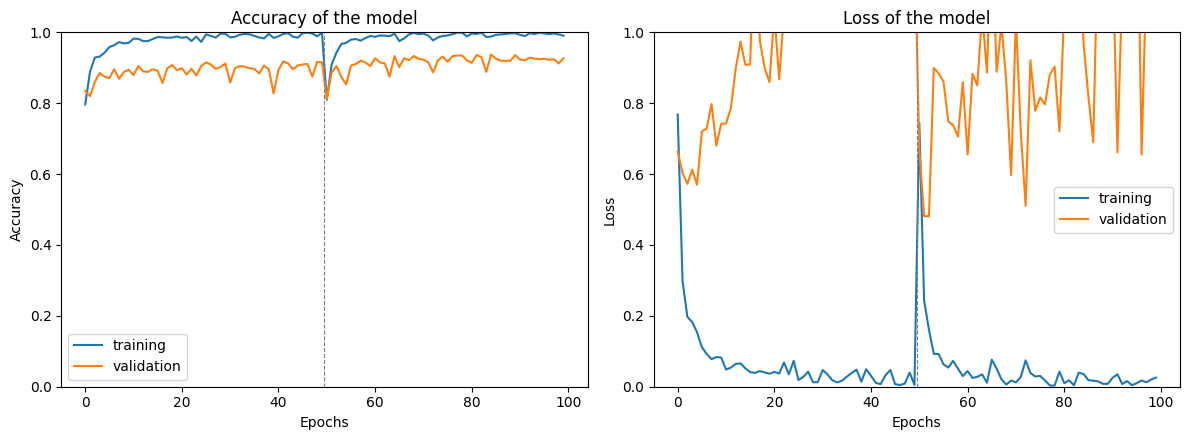

In [12]:
H = {k: hist1.history[k] + hist2.history.get(k, []) for k in hist1.history}
pd.DataFrame(H).to_csv(WORK_DIR / "history.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, m, t in [(ax[0], "accuracy", "Accuracy of the model"), (ax[1], "loss", "Loss of the model")]:
    a.plot(H[m], label="training"); a.plot(H["val_" + m], label="validation")
    a.axvline(len(hist1.history["loss"]) - 0.5, ls="--", c="gray", lw=0.8)
    a.set_title(t); a.set_xlabel("Epochs"); a.set_ylabel(m.capitalize()); a.legend()
ax[0].set_ylim(0, 1.0); ax[1].set_ylim(0, 1.0)
plt.tight_layout(); plt.savefig(WORK_DIR / "fig3_curves.png", dpi=150); plt.show()

## 9. Test-set evaluation (Table 3, Fig 4, Table 4)

25/25 [==============================] - 3s 124ms/step
                  precision    recall  f1-score   support

    glioma tumor       1.00      0.84      0.92       200
meningioma tumor       0.92      0.97      0.94       200
        no tumor       0.93      1.00      0.96       200
 pituitary tumor       0.98      0.99      0.99       200

        accuracy                           0.95       800
       macro avg       0.96      0.95      0.95       800
    weighted avg       0.96      0.95      0.95       800

                  precision    recall  f1-score   support

    glioma tumor     1.0000    0.8450    0.9160       200
meningioma tumor     0.9151    0.9700    0.9417       200
        no tumor     0.9302    1.0000    0.9639       200
 pituitary tumor     0.9755    0.9950    0.9851       200

        accuracy                         0.9525       800
       macro avg     0.9552    0.9525    0.9517       800
    weighted avg     0.9552    0.9525    0.9517       800



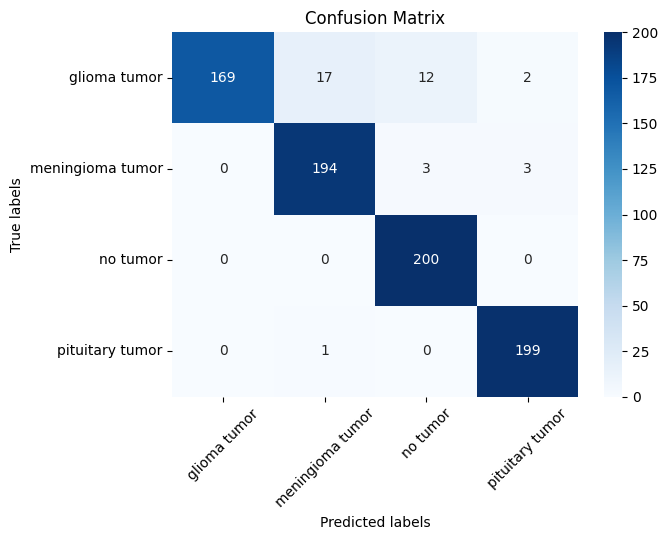

In [13]:
test_gen.reset()
probs = model.predict(test_gen, steps=math.ceil(test_gen.samples / BATCH_SIZE), verbose=1)
y_pred = probs.argmax(axis=1)
y_true = test_gen.classes
names = [DISPLAY[c] for c in CLASSES]

print(classification_report(y_true, y_pred, target_names=names, digits=2, zero_division=0))   # Table 3 (2 dp as in paper)
print(classification_report(y_true, y_pred, target_names=names, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names)
plt.xlabel("Predicted labels"); plt.ylabel("True labels"); plt.title("Confusion Matrix")
plt.xticks(rotation=45); plt.tight_layout(); plt.savefig(WORK_DIR / "fig4_confusion.png", dpi=150); plt.show()

In [14]:
def per_class_table(cm, names):
    total = cm.sum()
    rows = {}
    for i, n in enumerate(names):
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp; tn = total - tp - fn - fp
        rows[n] = {"Sensitivity (%)": 100 * tp / (tp + fn),
                   "Specificity (%)": 100 * tn / (tn + fp),
                   # The paper's "Accuracy" column equals per-class recall (e.g. 149/153 = 97.39):
                   "Accuracy (%) [paper def. = recall]": 100 * tp / (tp + fn),
                   # Eq. (5) applied one-vs-rest, for comparison:
                   "One-vs-rest accuracy (%) [Eq. 5]": 100 * (tp + tn) / total}
    df = pd.DataFrame(rows).T
    overall = df.mean()
    overall["Accuracy (%) [paper def. = recall]"] = 100 * np.trace(cm) / total   # paper's 99.24 = 650/655
    df.loc["Overall"] = overall
    return df.round(2)

table4 = per_class_table(cm, names)
paper_table4 = pd.DataFrame({
    "Sensitivity (%)": [100.00, 97.39, 100.00, 99.33, 99.18],
    "Specificity (%)": [99.80, 99.80, 100.00, 99.41, 99.75],
    "Accuracy (%)":    [100.00, 97.39, 100.00, 99.33, 99.24]},
    index=names + ["Overall"])
display(table4)
print("Paper Table 4:"); display(paper_table4)
print(f"Overall test accuracy: {100*np.trace(cm)/cm.sum():.2f}%  (paper: 99.24%)")

,Sensitivity (%),Specificity (%),Accuracy (%) [paper def. = recall],One-vs-rest accuracy (%) [Eq. 5]
glioma tumor,84.50,100.00,84.50,96.12
meningioma tumor,97.00,97.00,97.00,97.00
no tumor,100.00,97.50,100.00,98.12
pituitary tumor,99.50,99.17,99.50,99.25
Overall,95.25,98.42,95.25,97.62


Paper Table 4:


,Sensitivity (%),Specificity (%),Accuracy (%)
glioma tumor,100.00,99.80,100.00
meningioma tumor,97.39,99.80,97.39
no tumor,100.00,100.00,100.00
pituitary tumor,99.33,99.41,99.33
Overall,99.18,99.75,99.24


Overall test accuracy: 95.25%  (paper: 99.24%)


## 10. Manual spot-check (the paper's "manual testing")

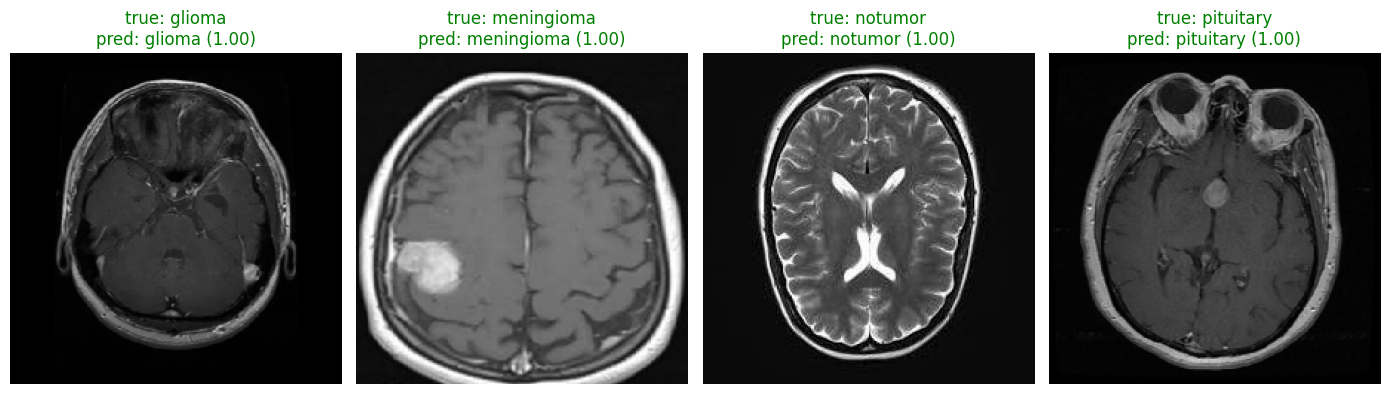

In [15]:
def predict_image(path, model=model):
    x = img_to_array(load_img(path, color_mode="grayscale", target_size=IMG_SIZE))
    x = np.repeat(x, 3, axis=-1)[None] / 255.0
    p = model.predict(x, verbose=0)[0]
    return CLASSES[int(p.argmax())], float(p.max())

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for a, c in zip(axes, CLASSES):
    f = random.choice(list((TEST_DIR / c).glob("*.png")))
    pred, conf = predict_image(f)
    a.imshow(Image.open(f), cmap="gray"); a.axis("off")
    a.set_title(f"true: {c}\npred: {pred} ({conf:.2f})", color="green" if pred == c else "red")
plt.tight_layout(); plt.show()

## 11. (Extra, not in paper) Leakage audit — duplicate images across Training/ and Testing/
This public dataset is reported to contain duplicate and near-duplicate images, and the Figshare portion has several slices per patient. Splitting by image rather than by patient can therefore inflate test accuracy. The audit below counts test images whose pixel content is identical to a training image, using a 64-bit difference hash. Near-duplicates and same-patient slices are not caught, so treat the count as a **lower bound**. It also re-scores the model on the test images that have no duplicate in training.

In [16]:
def dhash(path, size=8):
    im = Image.open(path).convert("L").resize((size + 1, size), Image.BILINEAR)
    a = np.asarray(im, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten().tobytes()

train_hashes = {dhash(p) for c in CLASSES for p in list_images(RAW_TRAIN / c)}
raw_test_by_stem = {(c, p.stem): p for c in CLASSES for p in list_images(RAW_TEST / c)}

dup_mask = np.array([
    dhash(raw_test_by_stem[(Path(f).parent.name, Path(f).stem)]) in train_hashes
    for f in test_gen.filenames])
print(f"Test images with a hash-identical image in Training/: {dup_mask.sum()} / {len(dup_mask)}")

clean = ~dup_mask
acc_all = (y_pred == y_true).mean() * 100
acc_clean = (y_pred[clean] == y_true[clean]).mean() * 100
print(f"Accuracy on all test images:          {acc_all:.2f}%")
print(f"Accuracy on de-duplicated test images: {acc_clean:.2f}%  (n={clean.sum()})")

Test images with a hash-identical image in Training/: 202 / 800
Accuracy on all test images:          95.25%
Accuracy on de-duplicated test images: 93.81%  (n=598)


## 12. Web application (Dash), as in Fig 5
The cell writes `app.py`. Run it from a terminal with `python app.py` and open http://127.0.0.1:8050.

In [17]:
app_code = """
import base64, io
import numpy as np
from PIL import Image
from dash import Dash, html, dcc, Input, Output
try:
    import tf_keras as keras
except ImportError:
    from tensorflow import keras

MODEL_PATH = "work/brain_tumor_vgg16.keras"
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
FACTS = {
    "glioma": "There is a glioma tumor. Glioma is a type of tumor that occurs in the brain and spinal cord. "
              "A glioma can affect your brain function and be life-threatening depending on its location and rate of growth.",
    "meningioma": "There is a meningioma tumor. Meningiomas arise from the meninges, the membranes surrounding the "
                  "brain and spinal cord. Most are slow-growing and benign.",
    "notumor": "No tumor detected in this MRI image.",
    "pituitary": "There is a pituitary tumor. Pituitary tumors are abnormal growths in the pituitary gland and can "
                 "affect hormone production.",
}
model = keras.models.load_model(MODEL_PATH)

def predict(img):
    img = img.convert("L").resize((224, 224))
    x = np.repeat(np.asarray(img, dtype="float32")[..., None], 3, axis=-1)[None] / 255.0
    p = model.predict(x, verbose=0)[0]
    return CLASSES[int(p.argmax())], float(p.max())

app = Dash(__name__)
app.layout = html.Div([
    html.H1("BRAIN TUMOR CLASSIFIER", style={"textAlign": "center"}),
    html.P("Step 1: Import a single image using upload button"),
    html.P("Step 2: Wait for prediction and interesting facts to appear"),
    dcc.Upload(id="upload", children=html.Div(["Drag and Drop or ", html.A("Select Files")]),
               style={"borderStyle": "dashed", "borderWidth": "1px", "textAlign": "center",
                      "padding": "10px"}, multiple=False),
    html.Div(id="output", style={"display": "flex", "gap": "40px", "alignItems": "center",
                                 "marginTop": "20px"}),
])

@app.callback(Output("output", "children"), Input("upload", "contents"))
def show(contents):
    if contents is None:
        return []
    _, b64 = contents.split(",", 1)
    img = Image.open(io.BytesIO(base64.b64decode(b64)))
    label, conf = predict(img)
    return [html.Img(src=contents, style={"maxWidth": "300px"}),
            html.Div([html.P(FACTS[label]), html.P(f"Confidence: {conf:.2%}")], style={"maxWidth": "400px"})]

if __name__ == "__main__":
    app.run(debug=False)
"""
Path("app.py").write_text(app_code.strip() + "\n")
print("Wrote app.py")

Wrote app.py
